In [1]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #02 - Successive Corrections

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using successive corrections.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [2]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles

In [3]:
### Create function for Cressman Analysis ###
def cressman_analysis(x_ob, y_ob, raw_obs, x_grid, y_grid, roi, target_x=None, target_y=None):

    if target_x is None:
         target_x = x_grid
         target_y = y_grid

    # empty arrs for storing info
    analysis_pts = np.full(target_x.shape, np.nan)
    number_of_obs = np.zeros(target_x.shape)

    for x in range(target_x.shape[0]):
            for y in range(target_x.shape[1]):
                
                # define grid pts and rel distance between grid pt and obs
                x_grid_pt, y_grid_pt = target_x[x, y], target_y[x, y]
                rel_dist = np.sqrt((x_ob - x_grid_pt)**2 + (y_ob - y_grid_pt)**2)

                # save sum of true bools if rel dist is inside roi
                inside_roi_bool = (rel_dist <= roi)  & np.isfinite(raw_obs)
                number_of_obs[x,y] = np.sum(inside_roi_bool) 

                if number_of_obs[x, y] == 0:
                     continue

                # compute cressman weights
                weights = ((roi**2 - rel_dist[inside_roi_bool]**2)/
                           (roi**2 + rel_dist[inside_roi_bool]**2))

                # analysis using weights
                analysis_pts[x, y] = (np.sum(weights * raw_obs[inside_roi_bool]) / np.sum(weights))

    return analysis_pts, number_of_obs

In [4]:
### Create function for bilinear interpolation ###
def bilinear_interp(analysis_pts, x_grid, y_grid, x_point, y_point):

    x = x_grid[:,0]
    y = y_grid[0,:]

    dx = x[1] - x[0]
    dy = y[1] - y[0]

    i = int(np.floor((x_point - x[0]) / dx))
    j = int(np.floor((y_point - y[0]) / dy))

    # see if pt is inside the analysis grid
    if i < 0 or i >= len(x) -1 or j < 0 or j >= len(y) -1:
        return np.nan

    dx_cell = (x_point - x[i])/dx
    dy_cell = (y_point - y[j])/dy

    # get surrounding pts relative to current pt
    pt_00 = analysis_pts[i, j]
    pt_10 = analysis_pts[i+1, j]
    pt_01 = analysis_pts[i, j+1]
    pt_11 = analysis_pts[i+1, j+1]

    interp_term_1 = ((1-dx_cell)*(1-dy_cell) * pt_00)
    interp_term_2 = (dx_cell * (1-dy_cell) * pt_10)
    interp_term_3 = ((1-dx_cell) * dy_cell * pt_01)
    interp_term_4 = (dx_cell * dy_cell * pt_11)

    return interp_term_1 + interp_term_2 + interp_term_3 + interp_term_4

In [5]:
### Read in observations ###
raw_obs = np.loadtxt("RAOBs_201903131200.txt", delimiter=',', dtype=str)
raw_500s = np.array([float(raw_obs[i][3]) for i in range(len(raw_obs))])

In [6]:
### Set up analysis map with a 21x27 rectangular grid of points ###
# params
R = 6371.0
phi_0 = np.deg2rad(60.0)
lambd_0 = np.deg2rad(-100.0)
k_0 = (1+np.sin(phi_0))/2

R_map = R * 100000 / 15000000

rho = 6371000

# grid points 
nx = 21
ny = 27
dx, x_0 = 1.27, 25
dy, y_0 = 1.27, -15.5
x = x_0 + np.arange(nx) * dx
y = y_0 + np.arange(ny) * dy
x_grid, y_grid = np.meshgrid(x, y, indexing='ij')

print(f'x: {x}\ny: {y}\nR_map: {R_map}')

x: [25.   26.27 27.54 28.81 30.08 31.35 32.62 33.89 35.16 36.43 37.7  38.97
 40.24 41.51 42.78 44.05 45.32 46.59 47.86 49.13 50.4 ]
y: [-15.5  -14.23 -12.96 -11.69 -10.42  -9.15  -7.88  -6.61  -5.34  -4.07
  -2.8   -1.53  -0.26   1.01   2.28   3.55   4.82   6.09   7.36   8.63
   9.9   11.17  12.44  13.71  14.98  16.25  17.52]
R_map: 42.473333333333336


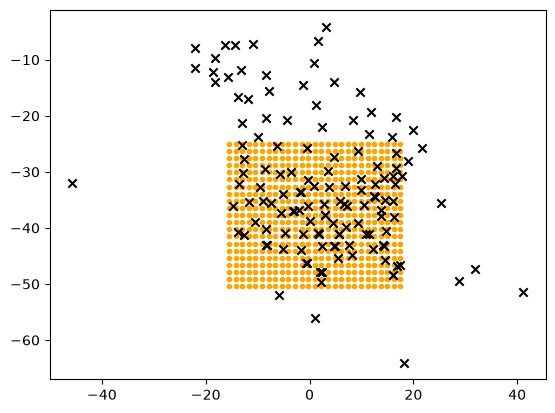

In [7]:
### convert obs lat/long to x,y ###
# open raw lat/lon
raw_lats = [float(raw_obs[i][1]) for i in range(len(raw_obs))]
raw_lons = [float(raw_obs[i][2]) for i in range(len(raw_obs))]

# convert to rad and create lambda
phi = np.deg2rad(raw_lats)
lamdb = np.deg2rad(raw_lons) - lambd_0

# eqn for r: r = rho * sigma * cos(phi).....or..... r= R*(1+sin(phi_0)/1+sin(phi))*cos(phi)
r = R * ((1 + np.sin(phi_0))/(1 + np.sin(phi))) * np.cos(phi) /150 

# convert
x_ob = r * np.cos(lamdb)
y_ob = r * np.sin(lamdb)

# simple test of grid and obs
plt.scatter(y_grid, -x_grid, marker=".", color='orange')
plt.scatter(y_ob, -x_ob, marker='x', color='k')

In [8]:
### Perform 500mb geopotential height analyses using a Cressman weighting Function###
#Use radii of influence 4, 2.5, 1.5 *dmin

dmin = 1.27
roi_1 = 4.0 * dmin
roi_2 = 2.5 * dmin
roi_3 = 1.5 * dmin

In [9]:
######## PASS 1 ########
analysis_pts_1, number_of_obs_1 = cressman_analysis(x_ob, y_ob, raw_500s, x_grid, y_grid, roi_1)




######## PASS 2 ########
analysis_1_interp = np.array([bilinear_interp(analysis_pts_1, x_grid, y_grid, x_ob[k], y_ob[k]) for k in range(len(raw_500s))])
missing_vals_bool = ~np.isfinite(analysis_1_interp)
cressman_interp_of_missing_vals, _ = cressman_analysis(x_grid.ravel(), y_grid.ravel(), analysis_pts_1.ravel(), x_grid, y_grid, roi_1,
                                                       target_x=x_ob[missing_vals_bool, None], target_y=y_ob[missing_vals_bool, None])
analysis_1_interp[missing_vals_bool] = cressman_interp_of_missing_vals[:,0]
analysis_1_resid = raw_500s - analysis_1_interp
analysis_1_correction, _ = cressman_analysis(x_ob, y_ob, analysis_1_resid, x_grid, y_grid, roi_2)

# copy analysis-1 and add corrections-1 to analysis-1 only if the pts arent nan
analysis_pts_2 = analysis_pts_1.copy()
where_analysis_1_pts_are_valid = np.isfinite(analysis_pts_1) & np.isfinite(analysis_1_correction)
analysis_pts_2[where_analysis_1_pts_are_valid] += analysis_1_correction[where_analysis_1_pts_are_valid]



######## PASS 3 ########
analysis_2_interp = np.array([bilinear_interp(analysis_pts_2, x_grid, y_grid, x_ob[k], y_ob[k]) for k in range(len(raw_500s))])
missing_vals_bool = ~np.isfinite(analysis_2_interp)
cressman_interp_of_missing_vals, _ = cressman_analysis(x_grid.ravel(), y_grid.ravel(), analysis_pts_2.ravel(), x_grid, y_grid, roi_2,
                                                       target_x=x_ob[missing_vals_bool, None], target_y=y_ob[missing_vals_bool, None])
analysis_2_interp[missing_vals_bool] = cressman_interp_of_missing_vals[:,0]
analysis_2_resid = raw_500s - analysis_2_interp
analysis_2_correction, _ = cressman_analysis(x_ob, y_ob, analysis_2_resid, x_grid, y_grid, roi_3)

# copy analysis-1 and add corrections-1 to analysis-1 only if the pts arent nan
analysis_pts_3 = analysis_pts_2.copy()
where_analysis_2_pts_are_valid = np.isfinite(analysis_pts_2) & np.isfinite(analysis_2_correction)
analysis_pts_3[where_analysis_2_pts_are_valid] += analysis_2_correction[where_analysis_2_pts_are_valid]


In [10]:
### Calculate Analysis Differences
analysis_diff_21 = analysis_pts_2 - analysis_pts_1
analysis_diff_31 = analysis_pts_3 - analysis_pts_1
analysis_diff_32 = analysis_pts_3 - analysis_pts_2

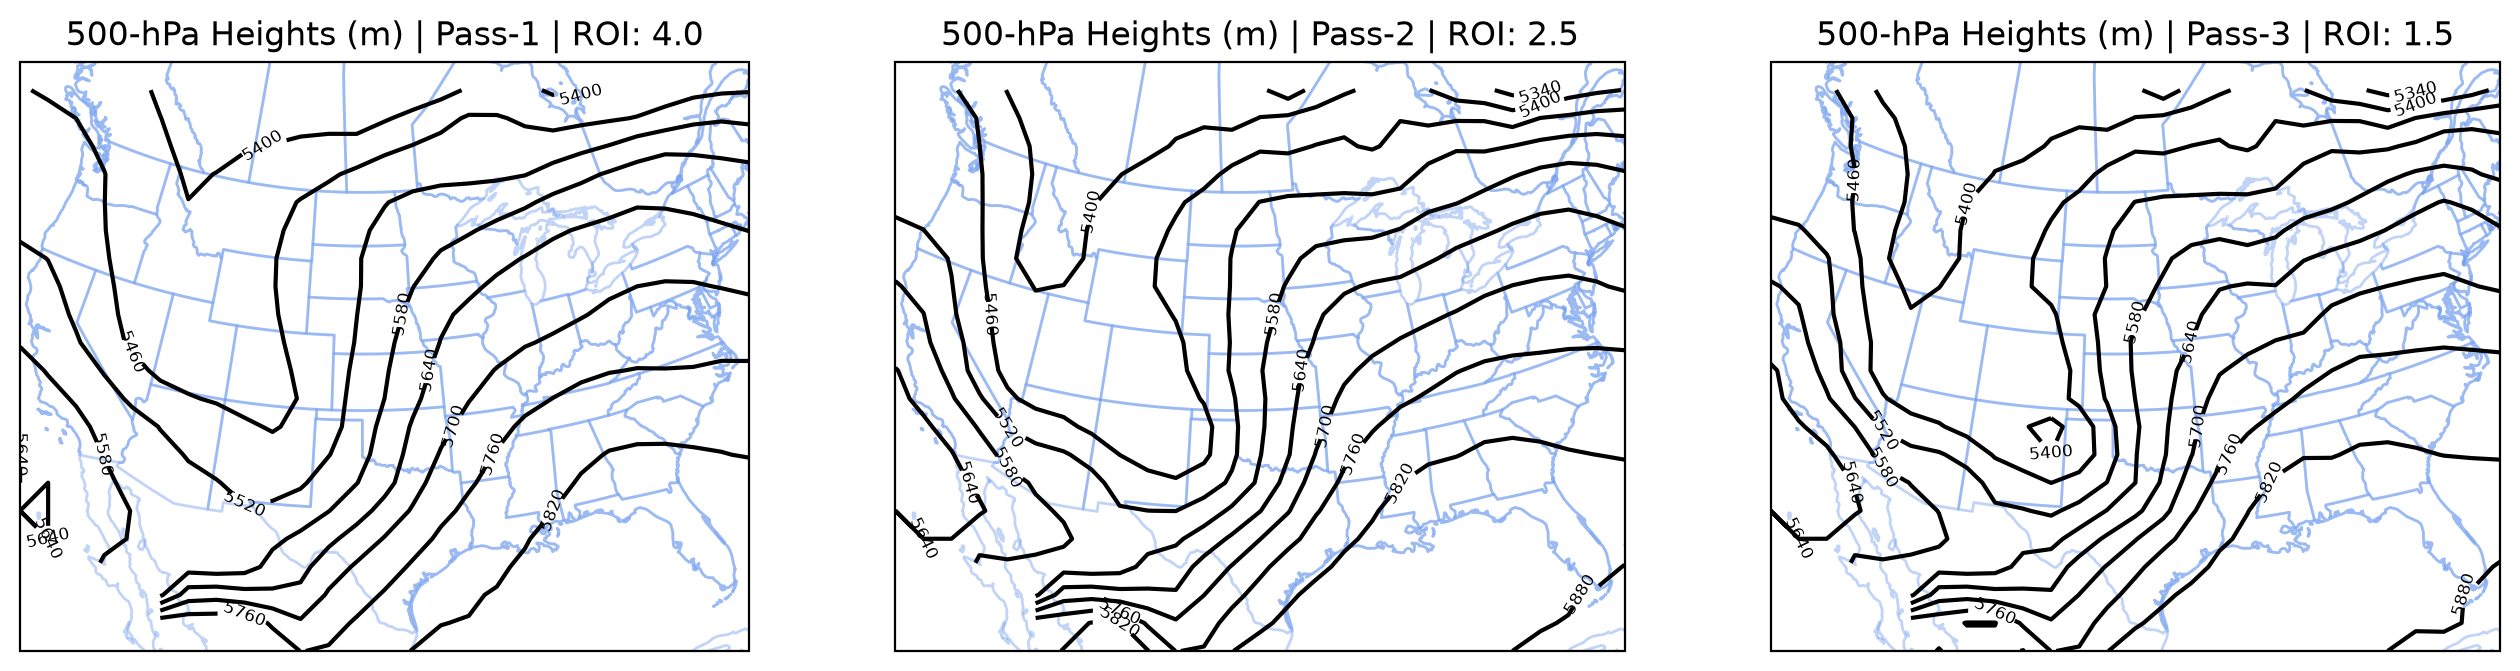

In [11]:
### Plot 500mb analyses over a map ###
#use old code...

r = np.sqrt(x_grid**2 + y_grid**2)
phi = (np.pi/2 - 2*np.arctan(r/(R_map * (1 +np.sin(phi_0)))))
lambd = np.arctan2(y_grid, x_grid)
lon = np.rad2deg(lambd_0 + lambd)
lat = np.rad2deg(phi)


globe = ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj = ccrs.Stereographic(central_longitude=-100, central_latitude=90, true_scale_latitude=60, globe=globe)

fig, axes = plt.subplots(1,3, figsize=(16,8), dpi=200, subplot_kw={'projection':proj})

#fig = plt.figure(figsize=(8,8),dpi=200)
#ax1 = fig.add_subplot(111,projection=proj)

analysis_data = [analysis_pts_1, analysis_pts_2, analysis_pts_3]
rois = ["Pass-1 | ROI: 4.0", "Pass-2 | ROI: 2.5", "Pass-3 | ROI: 1.5"]

for i in range(0,3):
    axes[i].add_feature(cfeature.STATES, edgecolor='cornflowerblue', alpha=0.4)
    axes[i].add_feature(cfeature.COASTLINE, edgecolor='cornflowerblue', alpha=0.4)
    cs1 = axes[i].contour(lon,lat,analysis_data[i],colors='k', levels=np.arange(0,8000,60),transform=ccrs.PlateCarree())
    plt.clabel(cs1,levels=np.arange(0,8000,60), fontsize=6)
    axes[i].set_title(f"500-hPa Heights (m) | {rois[i]}")
    
plt.show()

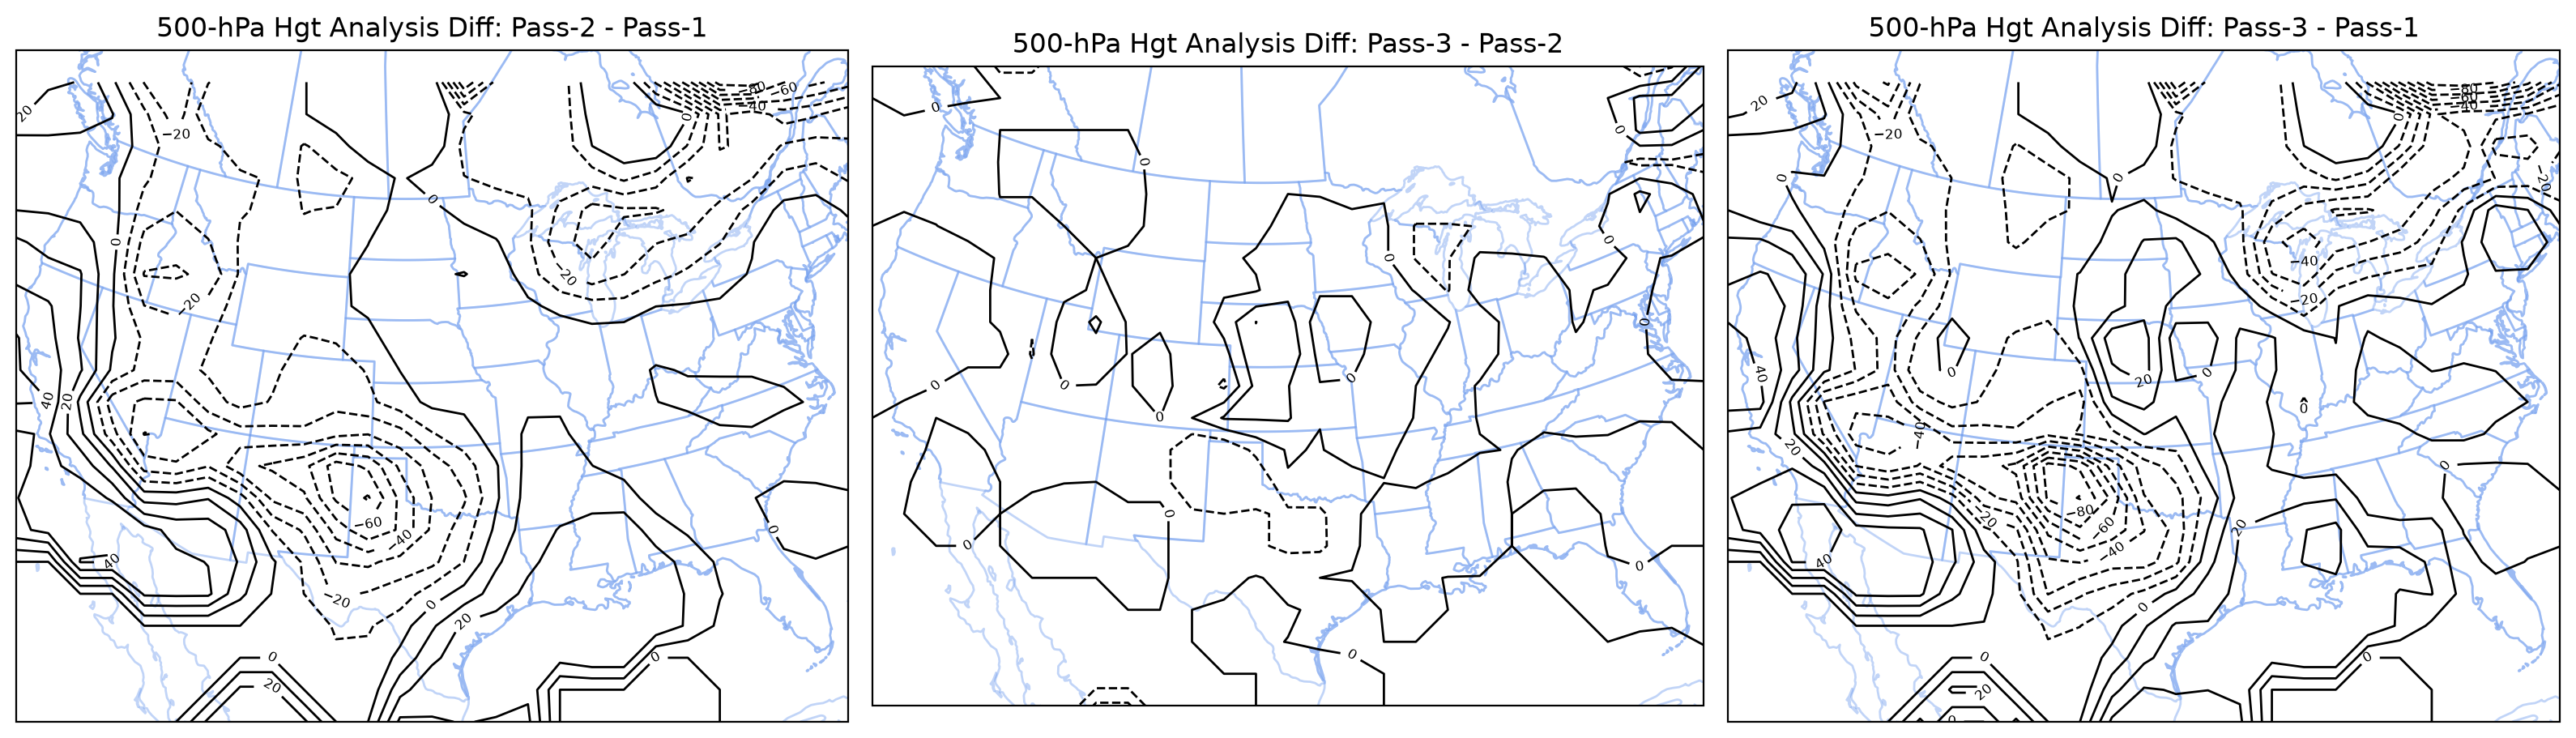

In [16]:
### Plot Analysis Differences ###
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj = ccrs.Stereographic(central_longitude=-100, central_latitude=90, true_scale_latitude=60, globe=globe)

fig, axes = plt.subplots(1,3, figsize=(16,6), dpi=200, subplot_kw={'projection':proj})

#fig = plt.figure(figsize=(8,8),dpi=200)
#ax1 = fig.add_subplot(111,projection=proj)

analysis_data = [analysis_diff_21, analysis_diff_32, analysis_diff_31]
rois = ["Pass-2 - Pass-1", "Pass-3 - Pass-2", "Pass-3 - Pass-1"]

for i in range(0,3):
    axes[i].add_feature(cfeature.STATES, edgecolor='cornflowerblue', alpha=0.4)
    axes[i].add_feature(cfeature.COASTLINE, edgecolor='cornflowerblue', alpha=0.4)
    cs1 = axes[i].contour(lon,lat,analysis_data[i], colors='k', levels=np.arange(-120, 121, 10), transform=ccrs.PlateCarree(), linewidths=1)
    plt.clabel(cs1,levels=np.arange(-120, 121, 20), fontsize=6)
    axes[i].set_title(f"500-hPa Hgt Analysis Diff: {rois[i]}")

plt.tight_layout()
plt.show()

In [ ]:
### Store the analyses in text files ###


In [ ]:
### Store the difference fields in text files ###


In [ ]:
### Store RMS values in text file ###


In [ ]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.
    

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    

3 - What happens as you increase the number of successive correction passes?  Is this 
    desirable?  Why or why not?
    

'''